In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [3]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 26.82it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:07<00:00, 48.25it/s]


In [ ]:
# from utils import unflatten_maps


# nifti_obj = unflatten_maps(
#     TD_maps=maps_ucsf, 
#     template=T1_file, 
#     return_nifti=True
# )

# nib.save(nifti_obj, 'loading_maps_result.nii.gz')

# from nilearn import image


# nifti_img_4d = unflatten_maps(maps_ucsf, T1_file, return_nifti=True)

# nifti_img_3d = image.index_img(nifti_img_4d, 0)

# plotting.plot_glass_brain(nifti_img_3d, colorbar=True, display_mode='lyrz', black_bg=True, title='Statistical Map')

# from nilearn import plotting


# nifti_img_3d = image.index_img(nifti_img_4d, 100)


# plotting.plot_stat_map(
#     nifti_img_3d, 
#     bg_img=T1_file, 
#     display_mode='z',
#     cut_coords=7,
#     threshold=0.3,
#     title="Axial Loading Map Series",
#     colorbar=True,
#     cmap='viridis'
# )

In [4]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:11<00:00, 44.45it/s]


# KernelPCA

In [31]:
from dataclasses import dataclass, field


@dataclass
class Dataset:
    name: str
    path: str
    maps: np.ndarray
    df: pd.DataFrame

    def __str__(self):
        return self.name.upper()

In [ ]:
from enum import Enum

from pipeline_encoder import EncodingPipeline


class DataHelper:
    class FeatureMethod(Enum):
        COSINE = "Cos"
        RBF = "RBF"
        PCA = "PCA"

    COMPONENT_PREFIX = "Comp"
    COLUMNS_TO_DROP = ["volume", "site", "OS", "ID", "ltdi", "tdi"]
    NUMERICAL_COLUMNS_TO_DROP = ["OS (corrected)", "status"]

    @staticmethod
    def add_extracted_mapsdata(df_base: pd.DataFrame, extracted_features: np.ndarray, method: FeatureMethod, n_components: int, column_names: list[str] | None = None) -> pd.DataFrame:
        if column_names is None:
            column_names = [f"{method.value}_{DataHelper.COMPONENT_PREFIX}_{i+1}" for i in range(n_components)]
        
        df_new_features = pd.DataFrame(
            extracted_features,
            columns=column_names, 
            index=df_base.index
        )

        df_all = pd.concat([df_base, df_new_features], axis=1)

        return df_all
    
    @staticmethod
    def feature_transform(df_base: pd.DataFrame, encoding_pipeline: EncodingPipeline):
        columns_to_drop = DataHelper.COLUMNS_TO_DROP
        df_base = df_base.drop(columns=columns_to_drop)

        categorical_features = df_base.select_dtypes(include="object").columns
        numerical_features = df_base.select_dtypes(exclude="object").columns

        numerical_features = numerical_features.drop(DataHelper.NUMERICAL_COLUMNS_TO_DROP)

        X_transformed = encoding_pipeline.fit_transform(list(numerical_features), list(categorical_features))

        return X_transformed


In [32]:
from typing import TypeAlias, Union
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA


Projector: TypeAlias = Union[TD_Kernel_PCA, TD_PCA]

class Transformer:
    def __init__(self, projector: Projector):
        self.projector = projector

    def fit_transform(self, norm):
        return self.projector.fit_pca_maps(norm=norm)
    
    def transform(self, maps):
        return self.projector.transform_maps(maps)

In [33]:
from lifelines import CoxPHFitter


class TD_CoxPHFitter:
    def __init__(self, penalizer: float | int = 0.01,):
        self.penalizer = penalizer
        self._cph = CoxPHFitter(penalizer=penalizer)
    
    def fit(self, X_train: pd.DataFrame, duration_col: str, event_col: str):
        self._cph.fit(X_train, duration_col, event_col=event_col)

    def score(self, X_test: pd.DataFrame, scoring_method: str = "log_likelihood"):
        return self._cph.score(X_test, scoring_method)
    
    def plot(self, ax):
        self._cph.plot(ax=ax)
    
    @property
    def concordance_index(self):
        if not hasattr(self._cph, "concordance_index_"):
            raise ValueError("CoxPHFitter not fitted yet. Fit it first")
        return self._cph.concordance_index_
    
    @property
    def cph(self):
        return self._cph

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!
ucsf + upenn training Concordance Index: 0.6834
ucsf + upenn testing Concordance Index: 0.6834


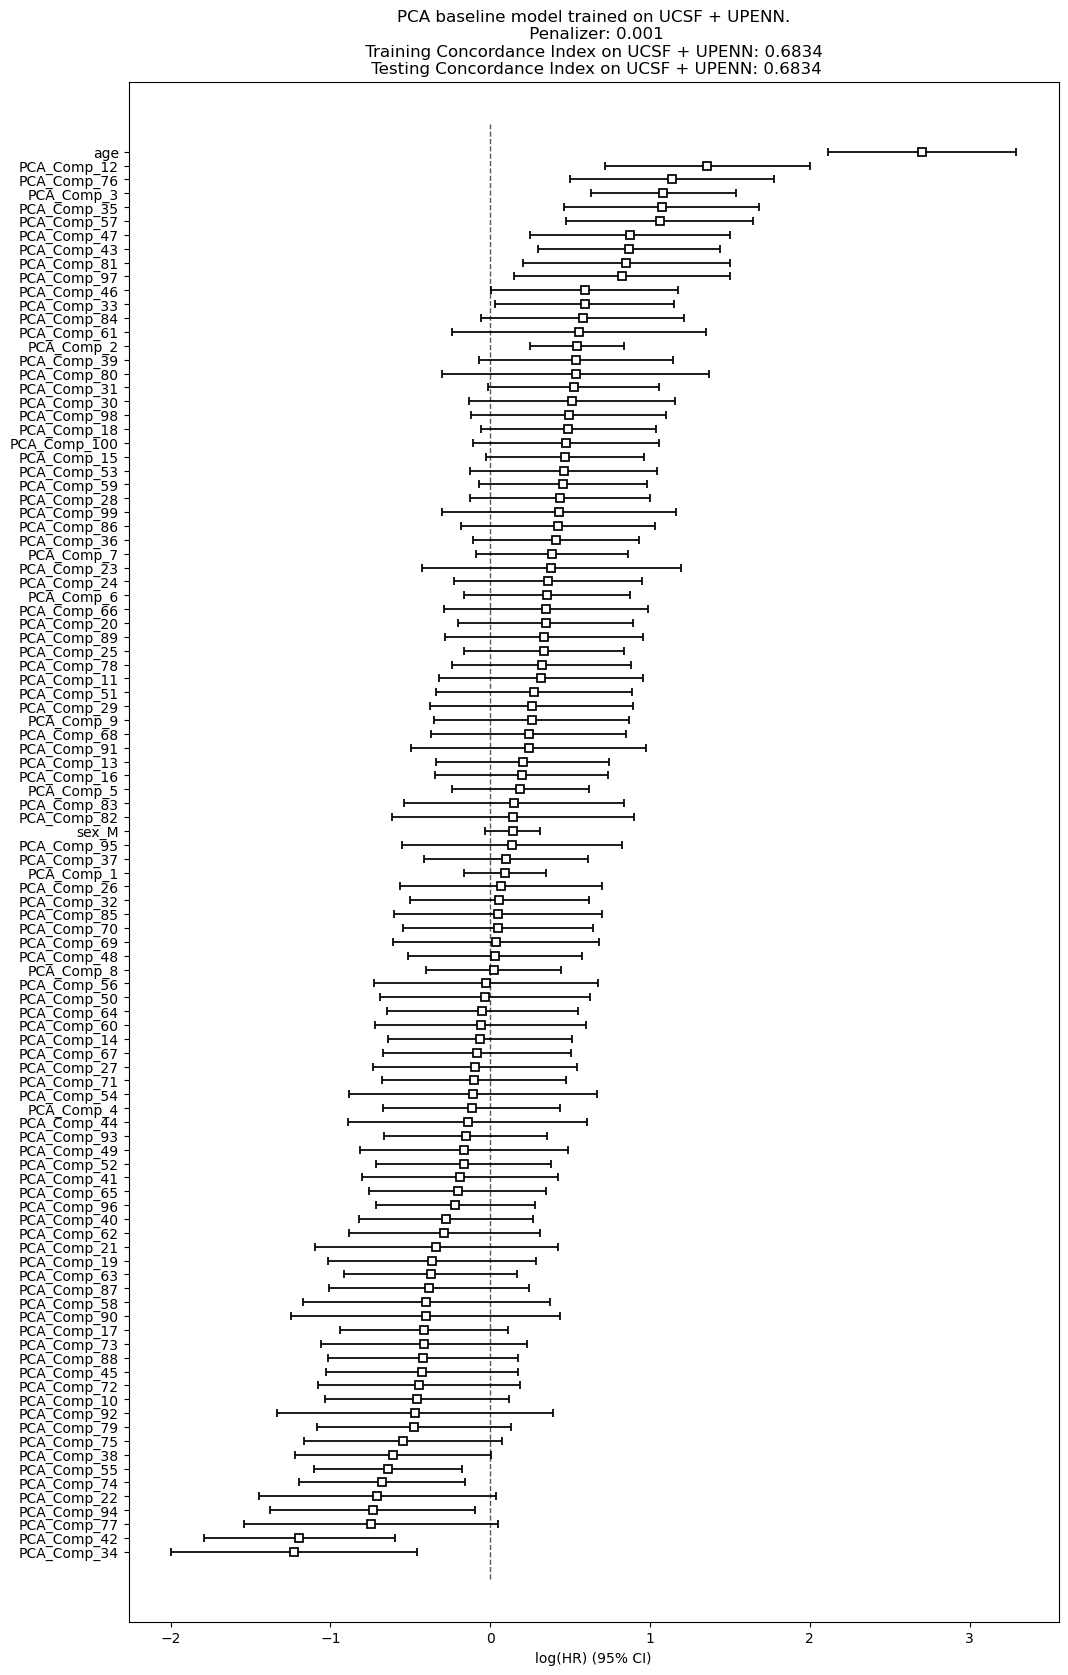

In [ ]:
import sklearn


normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

site_idx_training = 1
site_idx_testing = 0

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# # dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# # dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)

df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

# method = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
method = TD_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components)

trainer = Transformer(method)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_base = df_training

X_train_with_features = DataHelper.add_extracted_mapsdata(df_base, comps_training, method, n_components)
X_train = DataHelper.feature_transform(X_train_with_features)


penalizer = 0.001
duration_col = 'OS (corrected)'
event_col = 'status'

td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
X_test_with_features = DataHelper.add_extracted_mapsdata(df_base, comps_testing, method, n_components)
X_test = DataHelper.feature_transform(X_test_with_features)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"{method} baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)